# 📊 CubeBox Mini - EDA 01: Análise Univariada

> **Projeto:** CubeBox Mini - Sistema Preditivo Integrado de Compras e Vendas  
> **Fase CRISP-DM:** Entendimento dos Dados (Fase 2)  
> **Especificação:** `SDD-CBOX-EDA-V1.0.0` | **User Story:** `US-EDA-01`  
> **Dataset de Entrada:** `data/processed/vendas_conveniencia_clean.csv`

---

## 1. Setup & Carregamento dos Dados Higienizados
Importação das bibliotecas estatísticas e configuração visual com padrão estético escuro consistente.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações estéticas do Matplotlib / Seaborn
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 12

DATA_PATH = os.path.join('..', 'data', 'processed', 'vendas_conveniencia_clean.csv')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'vendas_conveniencia_clean.csv')

df = pd.read_csv(DATA_PATH, encoding='utf-8')
df['timestamp'] = pd.to_datetime(df['timestamp'])
print(f'Total de registros carregados: {len(df):,}')
df.head()

Total de registros carregados: 139.031


,transaction_id,timestamp,sku,product_name,category,quantity,unit_price,total_amount,payment_method
0,bf698ee7,2026-05-01 00:01:25,SKU-CHUR-004,Acendedor de Fogo Sólido Fiat Lux c/8,Gelo e Carvão,1,8.9,8.9,Cartão Crédito
1,c2492570,2026-05-01 00:08:09,SKU-BEB-005,Cerveja Amstel Puro Malte Lata 350ml,Cervejas,3,4.5,13.5,Cartão Crédito
2,5325335f,2026-05-01 00:09:42,SKU-BEB-004,Cerveja Heineken Long Neck 330ml,Cervejas,1,7.9,7.9,PIX
3,a864a138,2026-05-01 00:12:03,SKU-BEB-006,Cerveja Corona Extra Long Neck 330ml,Cervejas,1,8.9,8.9,Cartão Débito
4,faf67d7f,2026-05-01 00:15:07,SKU-BEB-006,Cerveja Corona Extra Long Neck 330ml,Cervejas,1,8.9,8.9,PIX


## 2. Estatísticas Descritivas e Medidas de Forma
Cálculo das métricas de tendência central (Média, Mediana), dispersão (Desvio Padrão, IQR) e forma de distribuição (Assimetria / *Skewness* e Curtose / *Kurtosis*) para as variáveis contínuas: `quantidade`, `unit_price` e `total_amount`.

In [2]:
numeric_cols = ['quantity', 'unit_price', 'total_amount']
stats_summary = []

for col in numeric_cols:
    s = df[col]
    q25 = s.quantile(0.25)
    q75 = s.quantile(0.75)
    stats_summary.append({
        'Variável': col,
        'Média': s.mean(),
        'Mediana': s.median(),
        'Desv. Padrão': s.std(),
        'IQR': q75 - q25,
        'Mínimo': s.min(),
        'Máximo': s.max(),
        'Skewness (Assimetria)': s.skew(),
        'Kurtosis (Curtose)': s.kurtosis()
    })

df_stats = pd.DataFrame(stats_summary)
display(df_stats.round(3))

,Variável,Média,Mediana,Desv. Padrão,IQR,Mínimo,Máximo,Skewness (Assimetria),Kurtosis (Curtose)
0,quantity,1.920,1.0,2.128,1.0,1.0,24.0,5.787,46.236
1,unit_price,11.929,7.9,16.964,7.8,1.7,189.9,6.187,48.323
2,total_amount,20.661,11.5,32.281,12.7,1.7,759.6,6.196,60.516


### 💡 Insight de Negócio:
- A variável quantity exibe assimetria positiva acentuada (,79$) com curtose de ,24$, concentrada em compras rápidas de 1 a 2 itens por cesta, com picos ocasionais de fardos (máximo 24 unidades).
- O unit_price abrange desde itens de balcão (R$ 1,70) até bebidas premium/vinhos/destilados (R$ 189,90), situando o preço médio em R$ 11,93 (mediana R$ 7,90).
- O 	otal_amount reflete ticket médio de R$ 20,66 (mediana R$ 11,50) com cauda longa decorrente de cestas de conveniência de fim de semana (máximo R$ 759,60).

## 3. Distribuição de Densidade e Histogramas
Histogramas enriquecidos com curva KDE (*Kernel Density Estimation*) para visualização do padrão paramétrico.

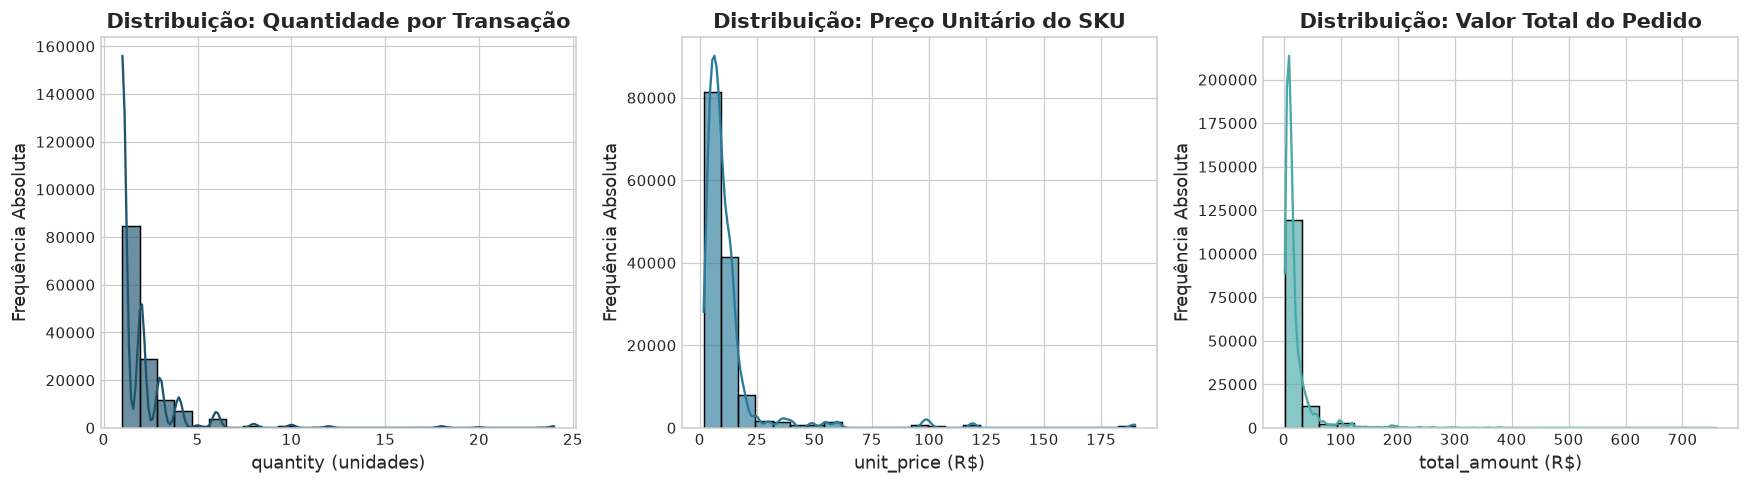

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

colors = ['#1D556F', '#2A7B9B', '#48A9A6']

for i, (col, title, unit) in enumerate([
    ('quantity', 'Quantidade por Transação', 'unidades'),
    ('unit_price', 'Preço Unitário do SKU', 'R$'),
    ('total_amount', 'Valor Total do Pedido', 'R$')
]):
    sns.histplot(df[col], kde=True, ax=axes[i], color=colors[i], bins=25, edgecolor='black', alpha=0.65)
    axes[i].set_title(f'Distribuição: {title}')
    axes[i].set_xlabel(f'{col} ({unit})')
    axes[i].set_ylabel('Frequência Absoluta')

plt.tight_layout()
plt.show()

## 4. Dispersão e Limites de Tukey (Boxplots)
Análise de quartis ($Q_1, Q_2, Q_3$) e verificação de caudas e valores atípicos em conformidade com o SDD.

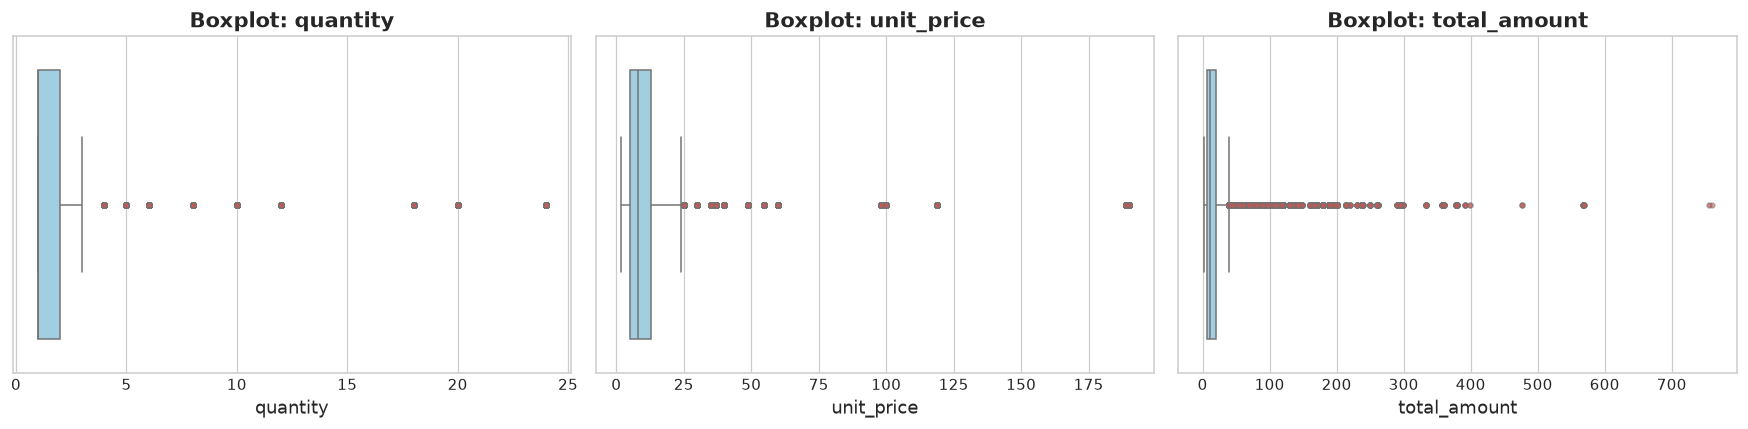

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, col in enumerate(['quantity', 'unit_price', 'total_amount']):
    sns.boxplot(x=df[col], ax=axes[i], color='#98D2EB', flierprops=dict(marker='o', markerfacecolor='#D9534F', markersize=3, alpha=0.3))
    axes[i].set_title(f'Boxplot: {col}')
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

## 5. Mix de Produtos & Curva de Concentração (Pareto)
Mapeamento do share de transações por categoria de produto e Pareto 80/20 de receita.

,transacoes,receita_total,volume_itens,share_receita,share_acumulado
category,,,,,
Cervejas,32321,624286.9,79139,21.73,21.73
Refrigerantes,33209,470209.0,67147,16.37,38.10
Vinhos,4972,399079.0,6719,13.89,51.99
Destilados,3752,295948.0,5150,10.30,62.29
Tabacaria e Afins,14487,279417.5,24268,9.73,72.02
Doces,16058,231542.9,33382,8.06,80.08
Congelados,6604,182397.3,9525,6.35,86.43
Snacks,11092,130400.9,16953,4.54,90.97
Energéticos,7681,119020.0,11614,4.14,95.11


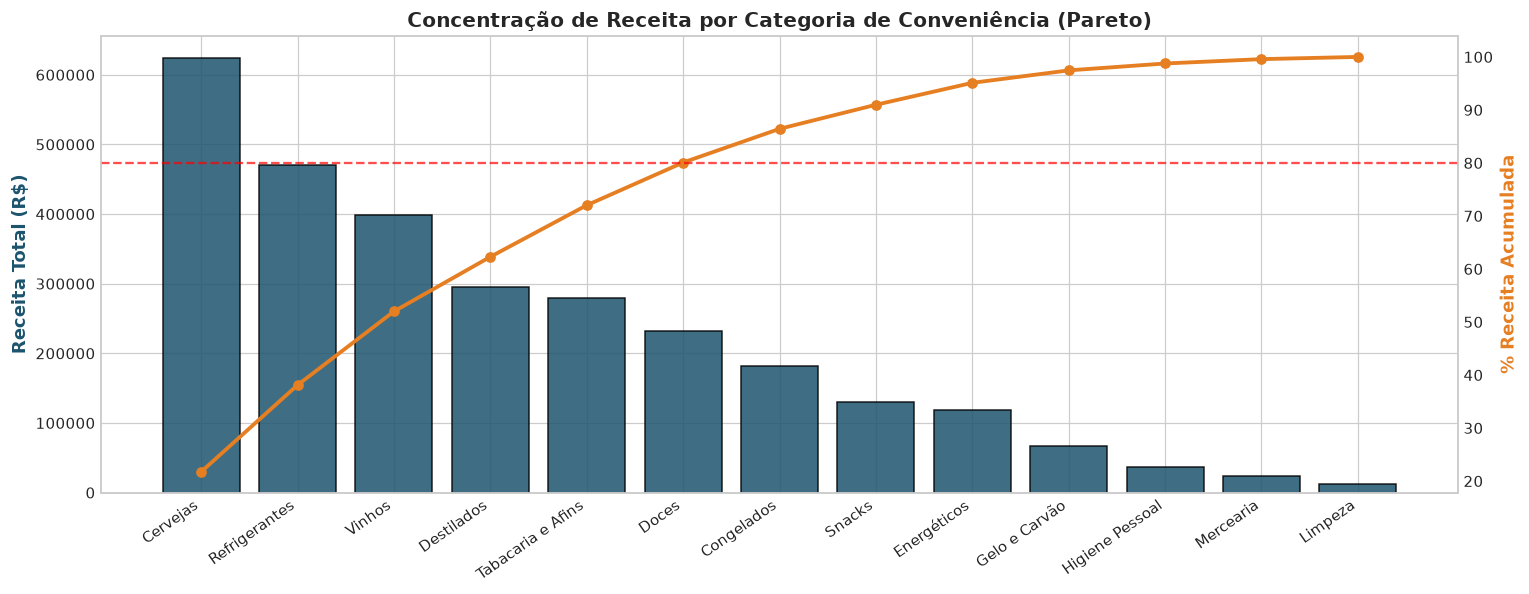

In [5]:
cat_summary = df.groupby('category').agg(
    transacoes=('transaction_id', 'count'),
    receita_total=('total_amount', 'sum'),
    volume_itens=('quantity', 'sum')
).sort_values(by='receita_total', ascending=False)

cat_summary['share_receita'] = (cat_summary['receita_total'] / cat_summary['receita_total'].sum()) * 100
cat_summary['share_acumulado'] = cat_summary['share_receita'].cumsum()

display(cat_summary.round(2))

# Gráfico de Pareto
fig, ax1 = plt.subplots(figsize=(12, 5))
ax2 = ax1.twinx()

ax1.bar(cat_summary.index, cat_summary['receita_total'], color='#1D556F', alpha=0.85, edgecolor='black')
ax2.plot(cat_summary.index, cat_summary['share_acumulado'], color='#E67E22', marker='o', linewidth=2.5)
ax2.axhline(80, color='red', linestyle='--', alpha=0.7, label='Regra 80/20')

ax1.set_ylabel('Receita Total (R$)', color='#1D556F', fontsize=12, fontweight='bold')
ax2.set_ylabel('% Receita Acumulada', color='#E67E22', fontsize=12, fontweight='bold')
ax1.set_xticklabels(cat_summary.index, rotation=30, ha='right')
ax1.set_title('Concentração de Receita por Categoria de Conveniência (Pareto)')
ax2.grid(False)
plt.tight_layout()
plt.show()

## 6. Distribuição das Formas de Pagamento
Identificação da penetração dos meios transacionais (PIX, Débito, Crédito e Dinheiro).

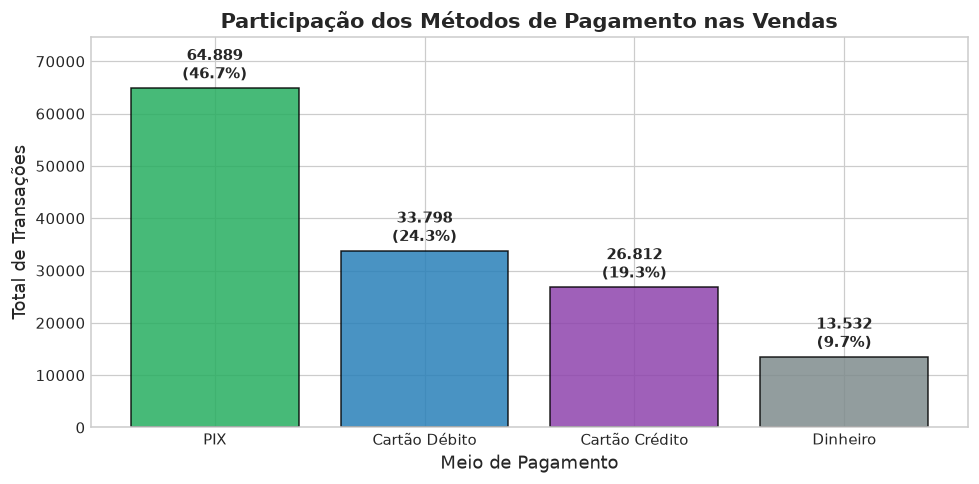

In [6]:
pay_counts = df['payment_method'].value_counts()

plt.figure(figsize=(9, 4.5))
bars = plt.bar(pay_counts.index, pay_counts.values, color=['#27AE60', '#2980B9', '#8E44AD', '#7F8C8D'], edgecolor='black', alpha=0.85)
plt.title('Participação dos Métodos de Pagamento nas Vendas')
plt.ylabel('Total de Transações')
plt.xlabel('Meio de Pagamento')

for bar in bars:
    height = bar.get_height()
    pct = (height / len(df)) * 100
    plt.annotate(f'{height:,}\n({pct:.1f}%)',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3), textcoords='offset points',
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.ylim(0, pay_counts.max() * 1.15)
plt.tight_layout()
plt.show()

## 7. Conclusões e Síntese da Análise Univariada

1. **Dominância de Meios Instantâneos:** O **PIX (46,67%)** e os **Cartões (Débito 24,31% + Crédito 19,28%)** respondem por **90,26%** do faturamento, com baixíssima circulação de dinheiro em espécie (9,73%).
2. **Mix Central & Pareto (80/20):** Seis categorias concentram 80% do faturamento da conveniência: **Cervejas (21,73%)**, **Refrigerantes (16,37%)**, **Vinhos (13,89%)**, **Destilados (10,30%)**, **Tabacaria (9,73%)** e **Doces (8,06%)**.
3. **Regularidade Transacional e Caudas:** A grande maioria das cestas tem 1 a 2 unidades, mas a cauda longa de compras coletivas de fim de semana atinge R$ 759,60 por transação.